## Device

In [1]:
import torch
import gc

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM total:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), "GB")

Using device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM total: 6.05 GB


## Dataset dan transform

In [2]:
import os
from torchvision import datasets, transforms

DATA_DIR = 'archive'
IMG_SIZE = 384
RESIZE_SIZE = 420

full_dataset = datasets.ImageFolder(DATA_DIR)
class_names = full_dataset.classes
NUM_CLASSES = len(class_names)
print(f"{NUM_CLASSES} kelas dengan {len(full_dataset)} gambar.")

data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((RESIZE_SIZE, RESIZE_SIZE)),
        transforms.RandomCrop(IMG_SIZE),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(7),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((RESIZE_SIZE, RESIZE_SIZE)),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

45 kelas dengan 14376 gambar.


## Persebaran kelas dataset

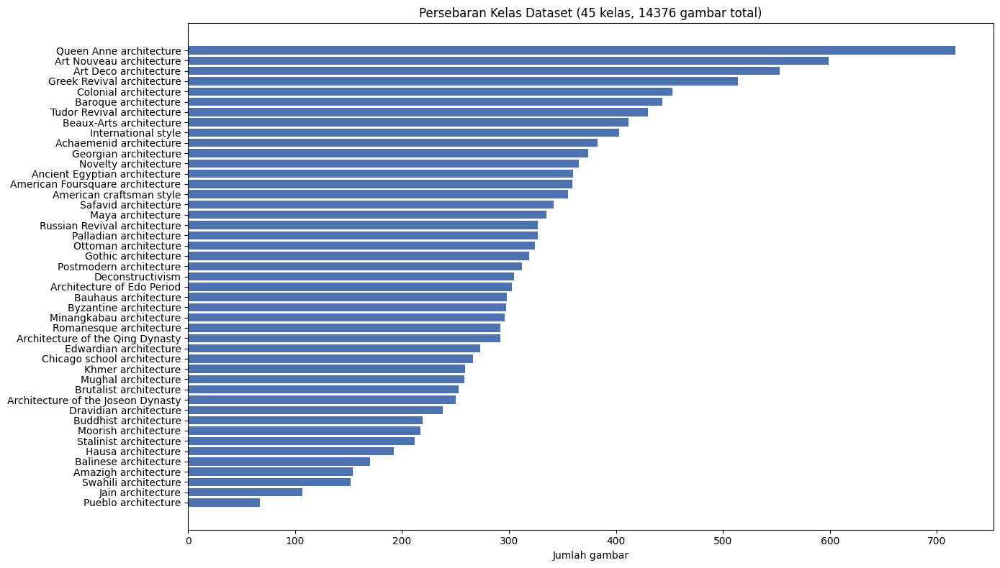

Jumlah gambar per kelas, min 67, max 717, mean 319.5


In [3]:
import matplotlib.pyplot as plt
import numpy as np

class_counts = np.bincount(full_dataset.targets, minlength=NUM_CLASSES)
order = np.argsort(class_counts)[::-1]

plt.figure(figsize=(14, 8))
plt.barh([class_names[i] for i in order][::-1], [class_counts[i] for i in order][::-1], color='#4C72B0')
plt.xlabel('Jumlah gambar')
plt.title(f'Persebaran Kelas Dataset ({NUM_CLASSES} kelas, {len(full_dataset)} gambar total)')
plt.tight_layout()
plt.show()

print(f"Jumlah gambar per kelas, min {class_counts.min()}, max {class_counts.max()}, mean {class_counts.mean():.1f}")

CutMix/MixUp

In [4]:
import torch
from torch.utils.data import Dataset
from torchvision.transforms import v2

class MapDataset(Dataset):
    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform
    def __getitem__(self, i):
        x, y = self.dataset[self.indices[i]]
        if self.transform: x = self.transform(x)
        return x, y
    def __len__(self): return len(self.indices)

cutmix = v2.CutMix(num_classes=NUM_CLASSES)
mixup = v2.MixUp(num_classes=NUM_CLASSES)
cutmix_or_mixup = v2.RandomChoice([cutmix, mixup])
CUTMIX_MIXUP_PROB = 0.5

def cutmix_mixup_collate_fn(batch):
    inputs, labels = torch.utils.data.default_collate(batch)
    if torch.rand(1).item() < CUTMIX_MIXUP_PROB:
        return cutmix_or_mixup(inputs, labels)
    return inputs, torch.nn.functional.one_hot(labels, NUM_CLASSES).float()

## Stratified split (test 10%, held-out) + 5-fold CV di sisa pool

In [5]:
import json
import time
import numpy as np
from sklearn.model_selection import StratifiedKFold, train_test_split

TEST_FRAC = 0.10
N_FOLDS = 5
RANDOM_STATE = 42
CHECKPOINT_DIR = 'checkpoint_SwinT_Dual'
RUN_ID = 'swint_dual'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

all_filepaths = np.array([p for p, _ in full_dataset.samples])
all_targets = np.array(full_dataset.targets)
all_idx = np.arange(len(full_dataset.samples))

pool_idx, test_idx = train_test_split(
    all_idx, test_size=TEST_FRAC, stratify=all_targets, random_state=RANDOM_STATE
)

print(f"Pool untuk CV: {len(pool_idx)} gambar | Held-out test: {len(test_idx)} gambar")

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
fold_splits_local = list(skf.split(pool_idx, all_targets[pool_idx]))
fold_splits = [(pool_idx[tr], pool_idx[va]) for tr, va in fold_splits_local]

RUN_TIMESTAMP = time.strftime("%Y%m%d_%H%M%S")
fold_split_record = {
    'class_names': class_names,
    'test_filepaths': all_filepaths[test_idx].tolist(),
    'folds': [
        {'train_filepaths': all_filepaths[tr].tolist(), 'val_filepaths': all_filepaths[va].tolist()}
        for tr, va in fold_splits
    ]
}
fold_split_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_splits_{RUN_TIMESTAMP}.json')
with open(fold_split_path, 'w') as f:
    json.dump(fold_split_record, f)
print(f"Fold split disimpan di {fold_split_path}")

Pool untuk CV: 12938 gambar | Held-out test: 1438 gambar
Fold split disimpan di checkpoint_SwinT_Dual/swint_dual_fold_splits_20261012_102119.json


## Jumlah data gambar (train, val, test)

In [6]:
print(f"Total gambar keseluruhan : {len(full_dataset)}")
print(f"Held-out test            : {len(test_idx)} gambar ({len(test_idx)/len(full_dataset)*100:.1f}%)")
print(f"Pool untuk CV (train+val) : {len(pool_idx)} gambar ({len(pool_idx)/len(full_dataset)*100:.1f}%)")
print()
for i, (train_idx_i, val_idx_i) in enumerate(fold_splits):
    print(f"Fold {i + 1}: train = {len(train_idx_i)} gambar | val = {len(val_idx_i)} gambar")

Total gambar keseluruhan : 14376
Held-out test            : 1438 gambar (10.0%)
Pool untuk CV (train+val) : 12938 gambar (90.0%)

Fold 1: train = 10350 gambar | val = 2588 gambar
Fold 2: train = 10350 gambar | val = 2588 gambar
Fold 3: train = 10350 gambar | val = 2588 gambar
Fold 4: train = 10351 gambar | val = 2587 gambar
Fold 5: train = 10351 gambar | val = 2587 gambar


## Fungsi satu epoch (dipakai training maupun retrain final)

In [7]:
import torch
import torch.nn as nn

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))

def run_epoch(model, loader, size, optimizer=None, clip_norm=None):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()

    running_loss = 0.0
    running_correct = 0

    with torch.set_grad_enabled(train_mode):
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            if train_mode:
                optimizer.zero_grad()

            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                outputs = model(inputs)
                loss = criterion(outputs, labels)
            preds = outputs.argmax(1)

            hard_labels = labels.argmax(1) if labels.dim() > 1 else labels

            if train_mode:
                scaler.scale(loss).backward()
                if clip_norm is not None:
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), clip_norm)
                scaler.step(optimizer)
                scaler.update()

            running_loss += loss.item() * inputs.size(0)
            running_correct += (preds == hard_labels).sum().item()

    epoch_loss = running_loss / size
    epoch_acc = running_correct / size
    return epoch_loss, epoch_acc

## Blok ResNeXt (cabang lokal / CNN branch)

In [8]:
import torch.nn as nn

class ResNeXtBottleneck(nn.Module):
    
    def __init__(self, in_channels, mid_channels, cardinality=16, stride=1):
        super().__init__()
        out_channels = in_channels if stride == 1 else in_channels * 2
        self.reduce = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
        )
        self.grouped = nn.Sequential(
            nn.Conv2d(mid_channels, mid_channels, kernel_size=3, stride=stride, padding=1,
                      groups=cardinality, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
        )
        self.expand = nn.Sequential(
            nn.Conv2d(mid_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.shortcut(x)
        out = self.reduce(x)
        out = self.grouped(out)
        out = self.expand(out)
        out = out + identity
        return self.relu(out)


class ResNeXtStage(nn.Module):
    def __init__(self, in_channels, mid_channels, num_blocks=3, cardinality=16, downsample=True):
        super().__init__()
        blocks = []
        stride_first = 2 if downsample else 1
        blocks.append(ResNeXtBottleneck(in_channels, mid_channels, cardinality, stride=stride_first))
        out_channels = in_channels if stride_first == 1 else in_channels * 2
        for _ in range(num_blocks - 1):
            blocks.append(ResNeXtBottleneck(out_channels, mid_channels, cardinality, stride=1))
        self.blocks = nn.Sequential(*blocks)
        self.out_channels = out_channels

    def forward(self, x):
        return self.blocks(x)


class CNNBranch(nn.Module):

    def __init__(self, cardinality=16):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )
        self.stage1 = ResNeXtStage(64, 64, num_blocks=3, cardinality=cardinality, downsample=True)
        self.stage2 = ResNeXtStage(self.stage1.out_channels, 128, num_blocks=3, cardinality=cardinality, downsample=True)
        self.stage3 = ResNeXtStage(self.stage2.out_channels, 256, num_blocks=3, cardinality=cardinality, downsample=True)
        self.out_channels = self.stage3.out_channels
        self.gap = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        feat_map = self.stage3(x)
        pooled = self.gap(feat_map).flatten(1)
        return pooled, feat_map

## BANGUN MODEL 

In [9]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models

class ImprovedSwinTransformer(nn.Module):

    def __init__(self, num_classes, cardinality=16):
        super().__init__()
        weights = models.Swin_T_Weights.IMAGENET1K_V1
        swin = models.swin_t(weights=weights)
        self.swin_features = swin.features   
        self.swin_norm = swin.norm
        swin_out_channels = swin.head.in_features 

        self.cnn_branch = CNNBranch(cardinality=cardinality)

        fused_dim = swin_out_channels + self.cnn_branch.out_channels
        self.fc = nn.Linear(fused_dim, num_classes)

    def forward(self, x, return_feat_maps=False):
        swin_feat_map = self.swin_features(x)      
        swin_feat_map = self.swin_norm(swin_feat_map)
        swin_pooled = swin_feat_map.mean(dim=[1, 2])   

        cnn_pooled, cnn_feat_map = self.cnn_branch(x)

        fused = torch.cat([swin_pooled, cnn_pooled], dim=1)
        out = self.fc(fused)

        if return_feat_maps:
            return out, swin_feat_map, cnn_feat_map
        return out


def build_model():
    model = ImprovedSwinTransformer(NUM_CLASSES, cardinality=16)
    return model.to(device)

## FUNGSI TRAINING 

In [10]:
import copy
import torch.optim as optim

def train_model(model, dataloaders, dataset_sizes, epochs=80, verbose_prefix="",
                 ckpt_path=None, validate=True):

    optimizer = optim.SGD(model.parameters(), lr=1e-2, momentum=0.9, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-2 * 0.01)

    history = {'train_loss': [], 'train_acc': []}
    if validate:
        history['val_loss'] = []
        history['val_acc'] = []
    best_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())
    start_epoch = 0

    if ckpt_path is not None and os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        scheduler.load_state_dict(ckpt['scheduler_state'])
        scaler.load_state_dict(ckpt['scaler_state'])
        history = ckpt['history']
        best_acc = ckpt['best_acc']
        best_model_wts = ckpt['best_model_wts']
        start_epoch = ckpt['epoch']
        torch.set_rng_state(ckpt['rng_state'].cpu())
        if device.type == "cuda" and ckpt.get('cuda_rng_state') is not None:
            torch.cuda.set_rng_state(ckpt['cuda_rng_state'].cpu())
        print(f"{verbose_prefix}Melanjutkan dari checkpoint: epoch {start_epoch + 1}/{epochs} "
              f"(best_acc sejauh ini {best_acc:.4f})")

    if start_epoch >= epochs:
        print(f"{verbose_prefix}Checkpoint sudah menyelesaikan {epochs} epoch, training dilewati.")
        model.load_state_dict(best_model_wts)
        del optimizer, scheduler
        return model, history, best_acc

    for epoch in range(start_epoch, epochs):
        train_loss, train_acc = run_epoch(model, dataloaders['train'], dataset_sizes['train'],
                                           optimizer=optimizer, clip_norm=1.0)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)

        if validate:
            val_loss, val_acc = run_epoch(model, dataloaders['val'], dataset_sizes['val'])
            history['val_loss'].append(val_loss)
            history['val_acc'].append(val_acc)
            if val_acc > best_acc:
                best_acc = val_acc
                best_model_wts = copy.deepcopy(model.state_dict())
        else:
            best_acc = train_acc
            best_model_wts = copy.deepcopy(model.state_dict())

        scheduler.step()

        if ckpt_path is not None:
            tmp_path = ckpt_path + '.tmp'
            torch.save({
                'epoch': epoch + 1,
                'model_state': model.state_dict(),
                'optimizer_state': optimizer.state_dict(),
                'scheduler_state': scheduler.state_dict(),
                'scaler_state': scaler.state_dict(),
                'history': history,
                'best_acc': best_acc,
                'best_model_wts': best_model_wts,
                'rng_state': torch.get_rng_state(),
                'cuda_rng_state': torch.cuda.get_rng_state() if device.type == "cuda" else None,
            }, tmp_path)
            os.replace(tmp_path, ckpt_path)

        if validate:
            print(f"{verbose_prefix}Epoch {epoch + 1}/{epochs} | train loss {train_loss:.4f} acc {train_acc:.4f} "
                  f"| val loss {val_loss:.4f} acc {val_acc:.4f} | lr {scheduler.get_last_lr()[0]:.2e}")
        else:
            print(f"{verbose_prefix}Epoch {epoch + 1}/{epochs} | train loss {train_loss:.4f} acc {train_acc:.4f} "
                  f"| lr {scheduler.get_last_lr()[0]:.2e}")

    model.load_state_dict(best_model_wts)
    del optimizer, scheduler
    torch.cuda.empty_cache()
    gc.collect()
    return model, history, best_acc

## Loop 5 fold

In [11]:
import numpy as np
from torch.utils.data import DataLoader

BATCH_SIZE = 14
NUM_WORKERS = os.cpu_count()
FOLD_EPOCHS = 80

FOLD_RESULTS_PATH = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_results.pt')

if os.path.exists(FOLD_RESULTS_PATH):
    fold_results = torch.load(FOLD_RESULTS_PATH, weights_only=False)
    done_folds = {r['fold'] for r in fold_results}
    print(f"Melanjutkan run sebelumnya: fold {sorted(done_folds)} sudah selesai, dilewati.")
else:
    fold_results = []
    done_folds = set()

for fold_idx, (train_idx, val_idx) in enumerate(fold_splits):
    fold_num = fold_idx + 1
    if fold_num in done_folds:
        continue

    print(f"\n FOLD {fold_num}/{N_FOLDS} (Improved Swin Transformer)")

    train_dataset = MapDataset(full_dataset, train_idx, transform=data_transforms['train'])
    val_dataset = MapDataset(full_dataset, val_idx, transform=data_transforms['val'])
    dataloaders = {
        'train': DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                             pin_memory=True, collate_fn=cutmix_mixup_collate_fn),
        'val': DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    }
    dataset_sizes = {'train': len(train_dataset), 'val': len(val_dataset)}

    model = build_model()
    epoch_ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold{fold_num}_epochckpt.pth')
    model, history, best_acc = train_model(
        model, dataloaders, dataset_sizes, epochs=FOLD_EPOCHS,
        verbose_prefix=f"  [FOLD {fold_num}] ", ckpt_path=epoch_ckpt_path
    )

    torch.cuda.empty_cache()
    gc.collect()

    ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold{fold_num}.pth')
    torch.save(model.state_dict(), ckpt_path)
    print(f"Bobot fold {fold_num} disimpan di {ckpt_path}")

    model.eval()
    y_true_f, y_pred_f = [], []
    with torch.no_grad():
        for inputs, labels in dataloaders['val']:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = outputs.argmax(1).cpu().numpy()
            y_true_f.extend(labels.numpy())
            y_pred_f.extend(preds)

    fold_results.append({
        'fold': fold_num,
        'best_val_acc': best_acc,
        'history': history,
        'y_true': np.array(y_true_f),
        'y_pred': np.array(y_pred_f),
    })
    torch.save(fold_results, FOLD_RESULTS_PATH)

    if os.path.exists(epoch_ckpt_path):
        os.remove(epoch_ckpt_path)

    del model, dataloaders, train_dataset, val_dataset
    torch.cuda.empty_cache()
    gc.collect()


 FOLD 1/5 (Improved Swin Transformer)
  [FOLD 1] Epoch 1/80 | train loss 2.7740 acc 0.3575 | val loss 1.8647 acc 0.5912 | lr 1.00e-02
  [FOLD 1] Epoch 2/80 | train loss 2.1736 acc 0.5514 | val loss 1.6284 acc 0.6735 | lr 9.98e-03
  [FOLD 1] Epoch 3/80 | train loss 2.0026 acc 0.6383 | val loss 1.5628 acc 0.7110 | lr 9.97e-03
  [FOLD 1] Epoch 4/80 | train loss 1.9109 acc 0.6671 | val loss 1.5290 acc 0.7230 | lr 9.94e-03
  [FOLD 1] Epoch 5/80 | train loss 1.8618 acc 0.6825 | val loss 1.4913 acc 0.7361 | lr 9.90e-03
  [FOLD 1] Epoch 6/80 | train loss 1.7737 acc 0.7122 | val loss 1.4542 acc 0.7515 | lr 9.86e-03
  [FOLD 1] Epoch 7/80 | train loss 1.7223 acc 0.7286 | val loss 1.4111 acc 0.7674 | lr 9.81e-03
  [FOLD 1] Epoch 8/80 | train loss 1.6984 acc 0.7447 | val loss 1.3954 acc 0.7709 | lr 9.76e-03
  [FOLD 1] Epoch 9/80 | train loss 1.6784 acc 0.7504 | val loss 1.3885 acc 0.7713 | lr 9.69e-03
  [FOLD 1] Epoch 10/80 | train loss 1.6407 acc 0.7675 | val loss 1.3713 acc 0.7798 | lr 9.62e-03


## Ringkasan akurasi antar fold

Akurasi validasi per fold: [0.8281, 0.8238, 0.8172, 0.8376, 0.8268]
Rata rata: 0.8267   Std: 0.0066


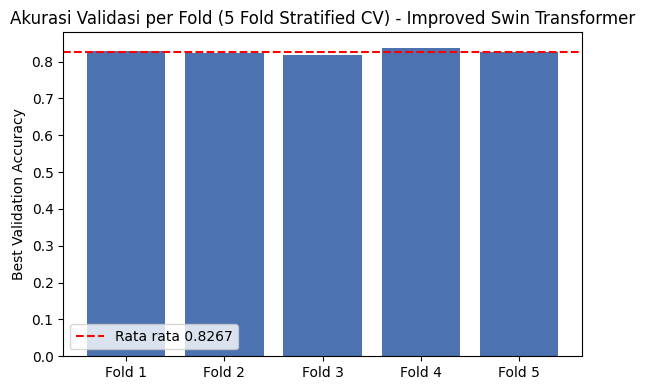

In [12]:
import matplotlib.pyplot as plt

accs = [r['best_val_acc'] for r in fold_results]
print(f"Akurasi validasi per fold: {[round(a, 4) for a in accs]}")
print(f"Rata rata: {np.mean(accs):.4f}   Std: {np.std(accs):.4f}")

plt.figure(figsize=(6, 4))
plt.bar([f"Fold {r['fold']}" for r in fold_results], accs, color='#4C72B0')
plt.axhline(np.mean(accs), color='red', linestyle='--', label=f"Rata rata {np.mean(accs):.4f}")
plt.ylabel('Best Validation Accuracy')
plt.title('Akurasi Validasi per Fold (5 Fold Stratified CV) - Improved Swin Transformer')
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

per_fold_metrics = []
for r in fold_results:
    y_true_f = r['y_true']
    y_pred_f = r['y_pred']
    per_fold_metrics.append({
        'fold': r['fold'],
        'accuracy': r['best_val_acc'],
        'precision_macro': precision_score(y_true_f, y_pred_f, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true_f, y_pred_f, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true_f, y_pred_f, average='macro', zero_division=0),
    })

for m in per_fold_metrics:
    print(f"Fold {m['fold']}: acc {m['accuracy']:.4f}  precision {m['precision_macro']:.4f}  "
          f"recall {m['recall_macro']:.4f}  f1 {m['f1_macro']:.4f}")

import pandas as pd
df_fold_metrics = pd.DataFrame(per_fold_metrics)
df_fold_metrics

Fold 1: acc 0.8281  precision 0.8386  recall 0.8254  f1 0.8293
Fold 2: acc 0.8238  precision 0.8410  recall 0.8246  f1 0.8306
Fold 3: acc 0.8172  precision 0.8285  recall 0.8149  f1 0.8188
Fold 4: acc 0.8376  precision 0.8490  recall 0.8370  f1 0.8389
Fold 5: acc 0.8268  precision 0.8371  recall 0.8224  f1 0.8255


,fold,accuracy,precision_macro,recall_macro,f1_macro
0,1,0.828053,0.838574,0.825393,0.829305
1,2,0.823802,0.840954,0.824618,0.830570
2,3,0.817233,0.828493,0.814937,0.818822
3,4,0.837650,0.849007,0.837020,0.838893
4,5,0.826826,0.837086,0.822383,0.825461


## Kurva Loss dan Akurasi Train/Val per Fold

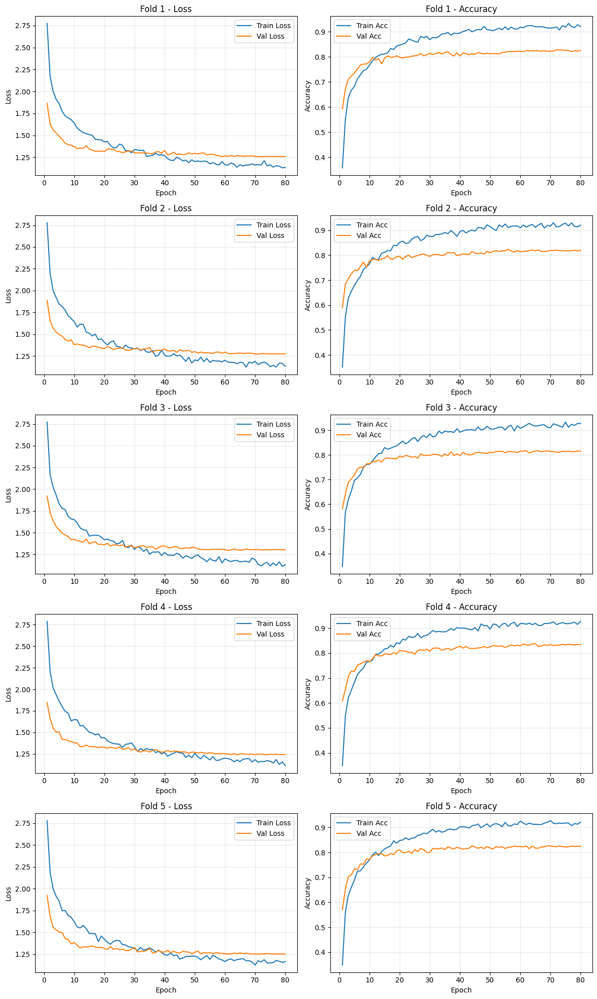

Kurva loss/akurasi per fold disimpan di checkpoint_SwinT_Dual/swint_dual_loss_acc_curves_20260901_054858.png


In [14]:
n_folds = len(fold_results)
fig, axes = plt.subplots(n_folds, 2, figsize=(12, 4 * n_folds))
if n_folds == 1:
    axes = axes.reshape(1, 2)

for i, r in enumerate(fold_results):
    h = r['history']
    ep = range(1, len(h['train_loss']) + 1)

    axes[i, 0].plot(ep, h['train_loss'], label='Train Loss')
    if 'val_loss' in h and len(h['val_loss']) > 0:
        axes[i, 0].plot(ep, h['val_loss'], label='Val Loss')
    axes[i, 0].set_title(f"Fold {r['fold']} - Loss")
    axes[i, 0].set_xlabel('Epoch')
    axes[i, 0].set_ylabel('Loss')
    axes[i, 0].legend()
    axes[i, 0].grid(alpha=0.3)

    axes[i, 1].plot(ep, h['train_acc'], label='Train Acc')
    if 'val_acc' in h and len(h['val_acc']) > 0:
        axes[i, 1].plot(ep, h['val_acc'], label='Val Acc')
    axes[i, 1].set_title(f"Fold {r['fold']} - Accuracy")
    axes[i, 1].set_xlabel('Epoch')
    axes[i, 1].set_ylabel('Accuracy')
    axes[i, 1].legend()
    axes[i, 1].grid(alpha=0.3)

plt.tight_layout()
curve_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_loss_acc_curves_{RUN_TIMESTAMP}.png')
plt.savefig(curve_path, dpi=150)
plt.show()
print(f"Kurva loss/akurasi per fold disimpan di {curve_path}")

## Classification report dan confusion matrix


Model Evaluation Report gabungan 5 fold (Classification Report):

                                    precision    recall  f1-score   support

           Achaemenid architecture     0.9403    0.9130    0.9265       345
              Amazigh architecture     0.8841    0.8777    0.8809       139
  American Foursquare architecture     0.7899    0.8266    0.8079       323
          American craftsman style     0.7500    0.7524    0.7512       319
     Ancient Egyptian architecture     0.9480    0.9568    0.9524       324
        Architecture of Edo Period     0.9094    0.9560    0.9321       273
Architecture of the Joseon Dynasty     0.9330    0.9289    0.9310       225
  Architecture of the Qing Dynasty     0.9297    0.9049    0.9171       263
             Art Deco architecture     0.8232    0.8133    0.8182       498
          Art Nouveau architecture     0.8496    0.8905    0.8696       539
             Balinese architecture     0.8581    0.8693    0.8636       153
              Baroqu

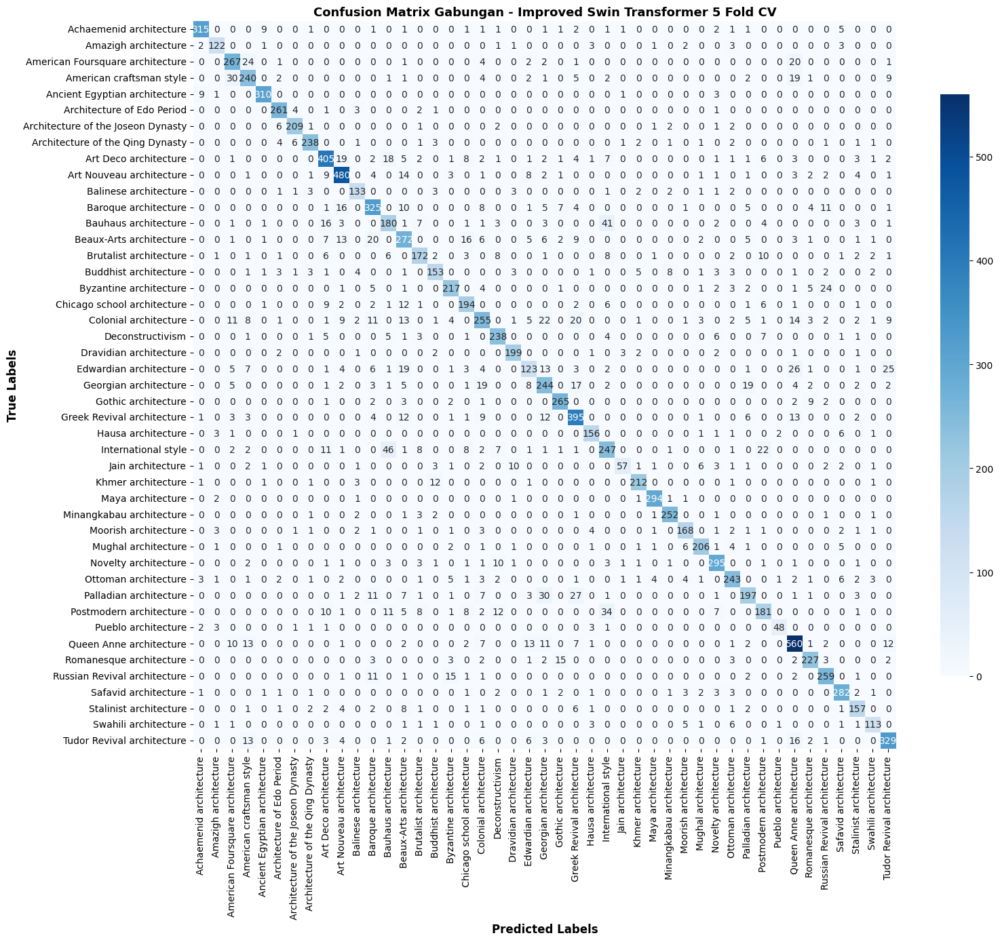

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true_all = np.concatenate([r['y_true'] for r in fold_results])
y_pred_all = np.concatenate([r['y_pred'] for r in fold_results])

print("\nModel Evaluation Report gabungan 5 fold (Classification Report):\n")
print(classification_report(y_true_all, y_pred_all, target_names=class_names, digits=4))

cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'shrink': 0.8})
plt.xlabel('Predicted Labels', fontsize=12, fontweight='bold')
plt.ylabel('True Labels', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix Gabungan - Improved Swin Transformer 5 Fold CV', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Retrain model final

In [16]:
import re
import nbformat as _nbf

def _reconstruct_fold_results_from_notebook(notebook_path, marker='FOLD {fold_num'):
    nb_ = _nbf.read(notebook_path, as_version=4)
    target_cell = None
    for c in nb_.cells:
        if c.get('cell_type') == 'code' and marker in c.get('source', ''):
            target_cell = c
            break
    if target_cell is None or not target_cell.get('outputs'):
        return None
    text = ''.join(o.get('text', '') for o in target_cell['outputs'] if o.get('output_type') == 'stream')
    return text

In [17]:
best_epochs_per_fold = []
for r in fold_results:
    val_accs = r['history']['val_acc']
    best_epoch = int(np.argmax(val_accs)) + 1
    best_epochs_per_fold.append(best_epoch)

FINAL_STAGE_EPOCHS = int(round(np.mean(best_epochs_per_fold)))
print(f"Epoch terbaik per fold: {best_epochs_per_fold}")
print(f"Rata rata epoch terbaik (dipakai untuk retrain final): {FINAL_STAGE_EPOCHS}")

Epoch terbaik per fold: [72, 56, 62, 65, 44]
Rata rata epoch terbaik (dipakai untuk retrain final): 60


In [18]:
from torch.utils.data import DataLoader

final_train_dataset = MapDataset(full_dataset, pool_idx, transform=data_transforms['train'])
final_train_loader = DataLoader(
    final_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
    pin_memory=True, collate_fn=cutmix_mixup_collate_fn
)
final_train_size = len(final_train_dataset)
print(f"Data training: {final_train_size} gambar")

final_dataloaders = {'train': final_train_loader}
final_dataset_sizes = {'train': final_train_size}

final_model = build_model()
final_epoch_ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final_epochckpt.pth')
final_model, final_history, final_best_acc = train_model(
    final_model, final_dataloaders, final_dataset_sizes, epochs=FINAL_STAGE_EPOCHS,
    verbose_prefix="  [FINAL TRAIN] ", ckpt_path=final_epoch_ckpt_path, validate=False
)

torch.cuda.empty_cache()
gc.collect()

final_ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final.pth')
torch.save(final_model.state_dict(), final_ckpt_path)
print(f"Model final disimpan di {final_ckpt_path}")

if os.path.exists(final_epoch_ckpt_path):
    os.remove(final_epoch_ckpt_path)

Data training: 12938 gambar
  [FINAL TRAIN] Epoch 1/60 | train loss 2.6580 acc 0.3889 | lr 9.99e-03
  [FINAL TRAIN] Epoch 2/60 | train loss 2.1176 acc 0.5818 | lr 9.97e-03
  [FINAL TRAIN] Epoch 3/60 | train loss 1.9670 acc 0.6382 | lr 9.94e-03
  [FINAL TRAIN] Epoch 4/60 | train loss 1.9020 acc 0.6695 | lr 9.89e-03
  [FINAL TRAIN] Epoch 5/60 | train loss 1.7953 acc 0.7016 | lr 9.83e-03
  [FINAL TRAIN] Epoch 6/60 | train loss 1.7650 acc 0.7223 | lr 9.76e-03
  [FINAL TRAIN] Epoch 7/60 | train loss 1.6858 acc 0.7442 | lr 9.67e-03
  [FINAL TRAIN] Epoch 8/60 | train loss 1.6763 acc 0.7490 | lr 9.57e-03
  [FINAL TRAIN] Epoch 9/60 | train loss 1.6605 acc 0.7585 | lr 9.46e-03
  [FINAL TRAIN] Epoch 10/60 | train loss 1.5859 acc 0.7835 | lr 9.34e-03
  [FINAL TRAIN] Epoch 11/60 | train loss 1.5840 acc 0.7846 | lr 9.20e-03
  [FINAL TRAIN] Epoch 12/60 | train loss 1.5658 acc 0.7934 | lr 9.05e-03
  [FINAL TRAIN] Epoch 13/60 | train loss 1.4875 acc 0.8150 | lr 8.90e-03
  [FINAL TRAIN] Epoch 14/60 | tr

## Kurva Loss dan Akurasi Retrain Final

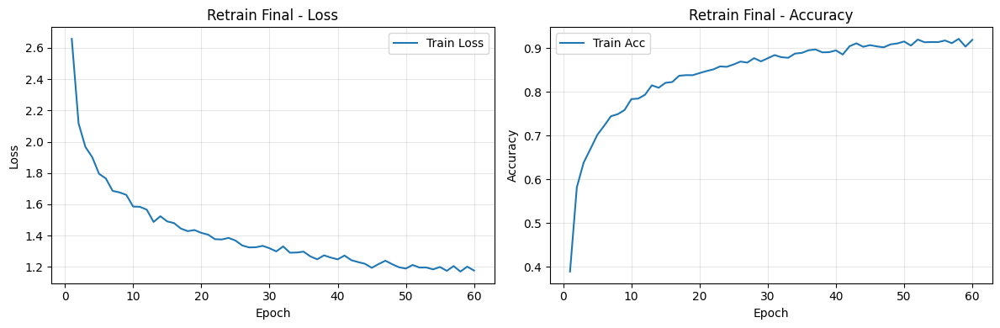

Kurva loss/akurasi retrain final disimpan di checkpoint_SwinT_Dual/swint_dual_final_loss_acc_curve_20260901_054858.png


In [19]:
h = final_history
ep = range(1, len(h['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, h['train_loss'], label='Train Loss')
if 'val_loss' in h and len(h['val_loss']) > 0:
    axes[0].plot(ep, h['val_loss'], label='Val Loss')
axes[0].set_title('Retrain Final - Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(ep, h['train_acc'], label='Train Acc')
if 'val_acc' in h and len(h['val_acc']) > 0:
    axes[1].plot(ep, h['val_acc'], label='Val Acc')
axes[1].set_title('Retrain Final - Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
final_curve_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final_loss_acc_curve_{RUN_TIMESTAMP}.png')
plt.savefig(final_curve_path, dpi=150)
plt.show()
print(f"Kurva loss/akurasi retrain final disimpan di {final_curve_path}")

## Load model tersimpan tanpa retrain

In [23]:
import glob
import json
import numpy as np
import os

CHECKPOINT_DIR = 'checkpoint_SwinT_Dual'
RUN_ID = 'swint_dual'

candidate_paths = sorted(glob.glob(os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_splits_*.json')))
EVAL_FOLD_SPLIT_PATH = candidate_paths[-1]
print(f"Memuat pembagian fold dari {EVAL_FOLD_SPLIT_PATH}")

with open(EVAL_FOLD_SPLIT_PATH) as f:
    saved_splits = json.load(f)

class_names = saved_splits['class_names']
NUM_CLASSES = len(class_names)

filepath_to_idx = {path: i for i, (path, _) in enumerate(full_dataset.samples)}
test_idx = np.array([filepath_to_idx[p] for p in saved_splits['test_filepaths']])
print(f"Held-out test: {len(test_idx)} gambar")

Memuat pembagian fold dari checkpoint_SwinT_Dual/swint_dual_fold_splits_20261012_102119.json
Held-out test: 1438 gambar


In [24]:
import os
print(os.path.exists('checkpoint_SwinT_Dual'))
print(os.listdir('checkpoint_SwinT_Dual') if os.path.exists('checkpoint_SwinT_Dual') else "folder tidak ada")

True
['swint_dual_fold4.pth', 'swint_dual_fold5.pth', 'swint_dual_fold2.pth', 'swint_dual_fold3.pth', 'swint_dual_fold_splits_20261011_173813.json', 'swint_dual_fold1.pth', 'swint_dual_loss_acc_curves_20260901_054858.png', 'swint_dual_fold_splits_20260901_054858.json', 'swint_dual_final_loss_acc_curve_20260901_054858.png', 'swint_dual_fold_results.pt', 'swint_dual_fold_splits_20261012_102119.json', 'swint_dual_final.pth']


In [25]:
import torch.nn as nn
from torchvision import models
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

final_model = build_model()
final_ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final.pth')
final_model.load_state_dict(torch.load(final_ckpt_path, map_location=device))
final_model.to(device)
print(f"Model final dimuat dari {final_ckpt_path}")

Using device: cuda
Model final dimuat dari checkpoint_SwinT_Dual/swint_dual_final.pth


In [26]:
import gc
from torch.utils.data import DataLoader

BATCH_SIZE = 14
NUM_WORKERS = os.cpu_count()

loaded_val_indices = []
for fold in saved_splits['folds']:
    loaded_val_indices.append(np.array([filepath_to_idx[p] for p in fold['val_filepaths']]))
N_FOLDS = len(loaded_val_indices)
print(f"Jumlah fold termuat: {N_FOLDS}")

def load_fold_model(fold_num):
    model = build_model()
    ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold{fold_num}.pth')
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()
    return model

loaded_fold_results = []
for fold_idx, val_idx in enumerate(loaded_val_indices):
    model = load_fold_model(fold_idx + 1)

    val_dataset = MapDataset(full_dataset, val_idx, transform=data_transforms['val'])
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs.to(device))
            preds = outputs.argmax(1).cpu().numpy()
            y_true.extend(labels.numpy())
            y_pred.extend(preds)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    val_acc = (y_true == y_pred).mean()

    loaded_fold_results.append({
        'fold': fold_idx + 1,
        'val_acc': val_acc,
        'y_true': y_true,
        'y_pred': y_pred,
        'val_idx': val_idx,
    })
    print(f"Fold {fold_idx + 1} val acc dari model tersimpan: {val_acc:.4f}")

    del model, val_loader, val_dataset
    torch.cuda.empty_cache()
    gc.collect()

Jumlah fold termuat: 5
Fold 1 val acc dari model tersimpan: 0.8281


[W1012 11:06:25.000430209 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 165675008 bytes (free: 124977152, total: 6051135488).


Fold 2 val acc dari model tersimpan: 0.8238


[W1012 11:07:04.761576222 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 165675008 bytes (free: 124977152, total: 6051135488).


Fold 3 val acc dari model tersimpan: 0.8172


[W1012 11:07:43.567542737 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 165675008 bytes (free: 124977152, total: 6051135488).


Fold 4 val acc dari model tersimpan: 0.8376


[W1012 11:08:22.268608493 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 165675008 bytes (free: 124977152, total: 6051135488).


Fold 5 val acc dari model tersimpan: 0.8264


## Filter near duplicate pada held-out test set

In [27]:
import json, os
flagged = set(os.path.normpath(p) for p in json.load(open("near_dup_report/flagged_test_files.json")))
test_idx_asli = test_idx.copy()
test_idx = np.array([i for i in test_idx if os.path.normpath(full_dataset.samples[i][0]) not in flagged])
print(len(test_idx_asli), "->", len(test_idx))

1438 -> 1058


## Evaluasi akhir di held-out test set

In [28]:
from sklearn.metrics import classification_report
from torch.utils.data import DataLoader

BATCH_SIZE = 14
NUM_WORKERS = os.cpu_count()

test_dataset = MapDataset(full_dataset, test_idx, transform=data_transforms['val'])
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

final_model.eval()
y_true_test, y_pred_test = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = final_model(inputs)
        preds = outputs.argmax(1).cpu().numpy()
        y_true_test.extend(labels.numpy())
        y_pred_test.extend(preds)

y_true_test = np.array(y_true_test)
y_pred_test = np.array(y_pred_test)
test_acc = (y_true_test == y_pred_test).mean()
print(f"Akurasi held-out test (model final): {test_acc:.4f}\n")
print(classification_report(y_true_test, y_pred_test, target_names=class_names, digits=4))

[W1012 11:09:00.550263040 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 165675008 bytes (free: 148045824, total: 6051135488).


Akurasi held-out test (model final): 0.7921

                                    precision    recall  f1-score   support

           Achaemenid architecture     0.9655    0.9655    0.9655        29
              Amazigh architecture     1.0000    0.9167    0.9565        12
  American Foursquare architecture     0.6000    0.7500    0.6667        24
          American craftsman style     0.7778    0.7500    0.7636        28
     Ancient Egyptian architecture     0.9333    0.9333    0.9333        15
        Architecture of Edo Period     0.9091    1.0000    0.9524        10
Architecture of the Joseon Dynasty     1.0000    1.0000    1.0000        14
  Architecture of the Qing Dynasty     1.0000    0.8750    0.9333        16
             Art Deco architecture     0.8500    0.7907    0.8193        43
          Art Nouveau architecture     0.7600    0.8837    0.8172        43
             Balinese architecture     0.9091    0.7143    0.8000        14
              Baroque architecture     0.7

In [29]:
import pandas as pd
os.makedirs("preds", exist_ok=True)
MODEL_NAME = "swint_dual"

assert len(test_idx_asli) == 1438
pred_ds = MapDataset(full_dataset, test_idx_asli, transform=data_transforms['val'])
pred_loader = DataLoader(pred_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)
final_model.eval()
yt_all, yp_all = [], []
with torch.no_grad():
    for inputs, labels in pred_loader:
        yp_all.extend(final_model(inputs.to(device)).argmax(1).cpu().numpy())
        yt_all.extend(labels.numpy())
yt_all, yp_all = np.array(yt_all), np.array(yp_all)
print(f"Akurasi test asli ({len(yt_all)} gambar): {(yt_all == yp_all).mean():.4f}")
pd.DataFrame({
    "filepath": [full_dataset.samples[i][0] for i in test_idx_asli],
    "y_true": yt_all, "y_pred": yp_all,
}).to_csv(f"preds/{MODEL_NAME}_test_preds.csv", index=False)

Akurasi test asli (1438 gambar): 0.8352


## Bootstrap 1000

In [30]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

assert 'y_true_test' in dir(), "Jalankan dulu cell 'Evaluasi akhir di held-out test set' sebelum ini."

y_true_all = y_true_test
y_pred_all = y_pred_test

N_BOOTSTRAP = 1000
rng = np.random.default_rng(42)
n_samples = len(y_true_all)

bootstrap_acc = np.zeros(N_BOOTSTRAP)
bootstrap_f1 = np.zeros(N_BOOTSTRAP)
bootstrap_precision = np.zeros(N_BOOTSTRAP)
bootstrap_recall = np.zeros(N_BOOTSTRAP)

for b in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_samples, n_samples)
    bootstrap_acc[b] = accuracy_score(y_true_all[idx], y_pred_all[idx])
    bootstrap_f1[b] = f1_score(y_true_all[idx], y_pred_all[idx], average='macro', zero_division=0)
    bootstrap_precision[b] = precision_score(y_true_all[idx], y_pred_all[idx], average='macro', zero_division=0)
    bootstrap_recall[b] = recall_score(y_true_all[idx], y_pred_all[idx], average='macro', zero_division=0)

acc_mean, acc_ci_low, acc_ci_high = bootstrap_acc.mean(), np.percentile(bootstrap_acc, 2.5), np.percentile(bootstrap_acc, 97.5)
f1_mean, f1_ci_low, f1_ci_high = bootstrap_f1.mean(), np.percentile(bootstrap_f1, 2.5), np.percentile(bootstrap_f1, 97.5)
precision_mean, precision_ci_low, precision_ci_high = bootstrap_precision.mean(), np.percentile(bootstrap_precision, 2.5), np.percentile(bootstrap_precision, 97.5)
recall_mean, recall_ci_low, recall_ci_high = bootstrap_recall.mean(), np.percentile(bootstrap_recall, 2.5), np.percentile(bootstrap_recall, 97.5)

print(f"Accuracy  : mean {acc_mean:.4f}, 95% CI [{acc_ci_low:.4f}, {acc_ci_high:.4f}]")
print(f"F1 macro  : mean {f1_mean:.4f}, 95% CI [{f1_ci_low:.4f}, {f1_ci_high:.4f}]")
print(f"Precision macro: mean {precision_mean:.4f}, 95% CI [{precision_ci_low:.4f}, {precision_ci_high:.4f}]")
print(f"Recall macro   : mean {recall_mean:.4f}, 95% CI [{recall_ci_low:.4f}, {recall_ci_high:.4f}]")

Accuracy  : mean 0.7919, 95% CI [0.7684, 0.8157]
F1 macro  : mean 0.7982, 95% CI [0.7703, 0.8241]
Precision macro: mean 0.8195, 95% CI [0.7944, 0.8422]
Recall macro   : mean 0.7992, 95% CI [0.7725, 0.8246]


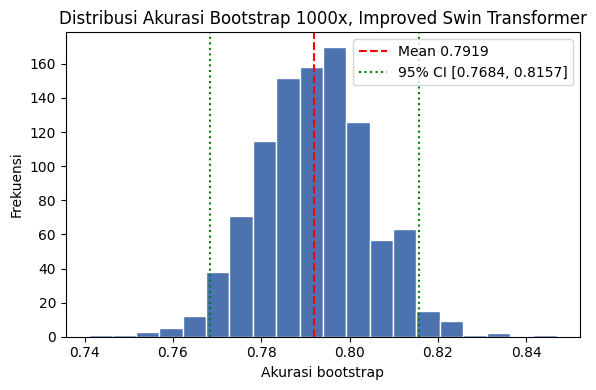

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.hist(bootstrap_acc, bins=20, color='#4C72B0', edgecolor='white')
plt.axvline(acc_mean, color='red', linestyle='--', label=f"Mean {acc_mean:.4f}")
plt.axvline(acc_ci_low, color='green', linestyle=':', label=f"95% CI [{acc_ci_low:.4f}, {acc_ci_high:.4f}]")
plt.axvline(acc_ci_high, color='green', linestyle=':')
plt.xlabel('Akurasi bootstrap')
plt.ylabel('Frekuensi')
plt.title('Distribusi Akurasi Bootstrap 1000x, Improved Swin Transformer')
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
import pandas as pd
import time

RUN_TIMESTAMP = time.strftime("%Y%m%d_%H%M%S")

df_bootstrap = pd.DataFrame({
    'iterasi': np.arange(1, N_BOOTSTRAP + 1),
    'accuracy': bootstrap_acc,
    'f1_macro': bootstrap_f1,
    'precision_macro': bootstrap_precision,
    'recall_macro': bootstrap_recall,
})

bootstrap_csv_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_bootstrap_test_{RUN_TIMESTAMP}.csv')
df_bootstrap.to_csv(bootstrap_csv_path, index=False)
print(f"Hasil bootstrap 1000x tersimpan di {bootstrap_csv_path}")
df_bootstrap

Hasil bootstrap 1000x tersimpan di checkpoint_SwinT_Dual/swint_dual_bootstrap_test_20261012_110940.csv


,iterasi,accuracy,f1_macro,precision_macro,recall_macro
0,1,0.789225,0.789072,0.806417,0.792948
1,2,0.814745,0.815940,0.834182,0.818061
2,3,0.768431,0.762204,0.791804,0.764806
3,4,0.793006,0.802719,0.822972,0.802191
4,5,0.834594,0.841896,0.861718,0.841460
...,...,...,...,...,...
995,996,0.799622,0.807325,0.825232,0.807354
996,997,0.810964,0.813743,0.836196,0.812834
997,998,0.789225,0.792723,0.817449,0.793060
998,999,0.815690,0.819544,0.833545,0.820330


## Grad-CAM 

In [33]:
import torch.nn.functional as F
from PIL import Image

def compute_gradcam(model, input_tensor, target_class=None):
    model.eval()
    activations = {}
    gradients = {}

    def forward_hook(module, inp, out):
        activations['value'] = out

    def backward_hook(module, grad_in, grad_out):
        gradients['value'] = grad_out[0]

    target_layer = model.swin_features[-1]
    h1 = target_layer.register_forward_hook(forward_hook)
    h2 = target_layer.register_full_backward_hook(backward_hook)

    output = model(input_tensor)
    if target_class is None:
        target_class = output.argmax(dim=1).item()
    model.zero_grad()
    output[0, target_class].backward()

    h1.remove(); h2.remove()

    act = activations['value']
    grad = gradients['value']

    weights = grad.mean(dim=[1, 2], keepdim=True)
    cam = (weights * act).sum(dim=-1).squeeze(0)
    cam = F.relu(cam)
    cam = cam.detach().cpu().numpy()
    if cam.max() > 0:
        cam = cam / cam.max()
    return cam, target_class


def gradcam_to_heatmap(cam, img_size):
    import cv2
    heatmap = cv2.resize(cam, (img_size, img_size))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    return heatmap

In [34]:
gradcam_model = final_model
gradcam_model.eval()

GRADCAM_DIR = 'hasil_gradcam_swint_dual'
os.makedirs(GRADCAM_DIR, exist_ok=True)

samples_per_class = {}
for idx in test_idx:
    label = full_dataset.targets[idx]
    samples_per_class.setdefault(label, []).append(int(idx))

print(f"Grad-CAM memakai model final, sampel diambil dari held-out test set ({len(test_idx)} gambar)")

Grad-CAM memakai model final, sampel diambil dari held-out test set (1058 gambar)


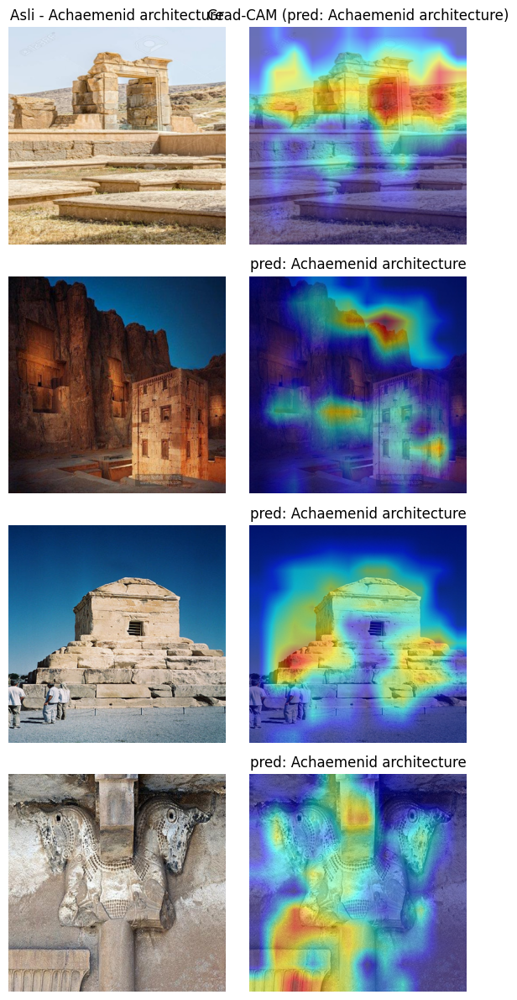

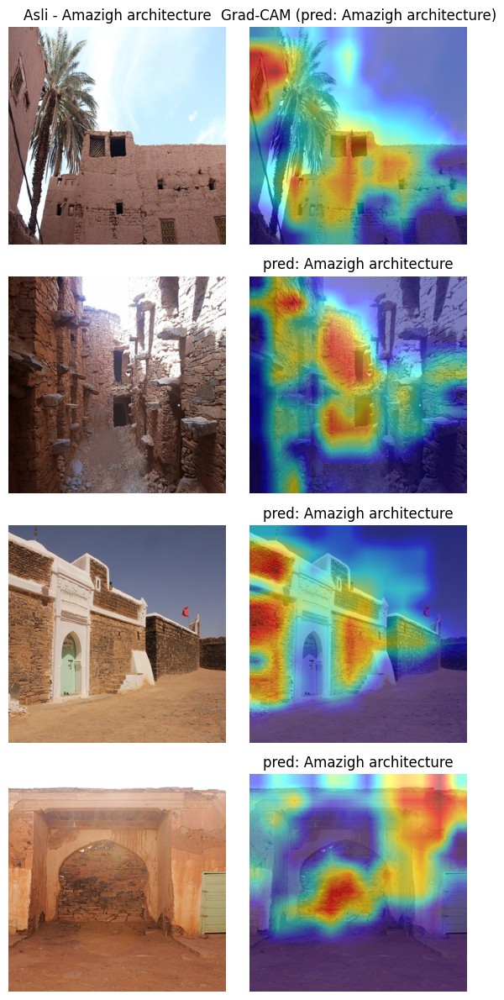

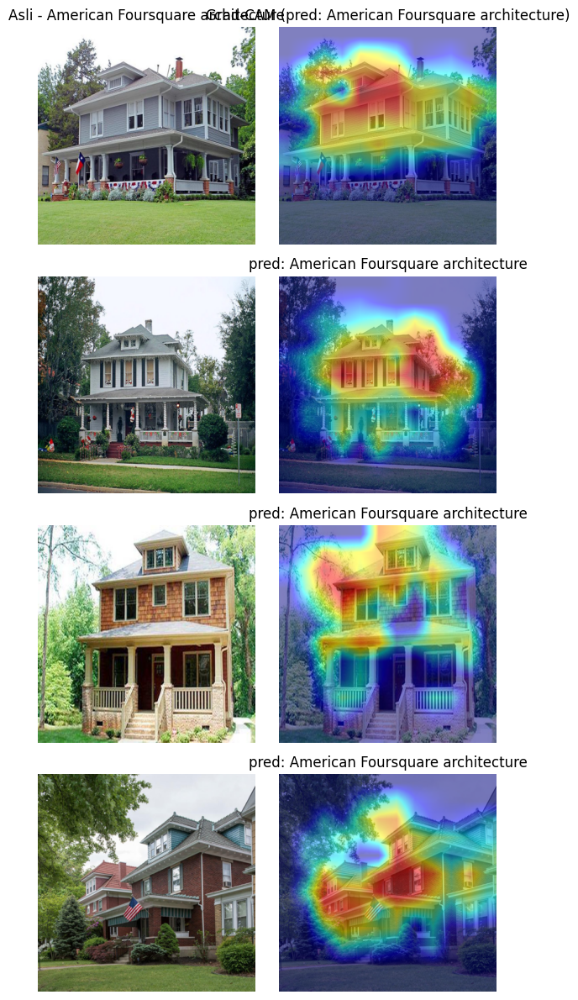

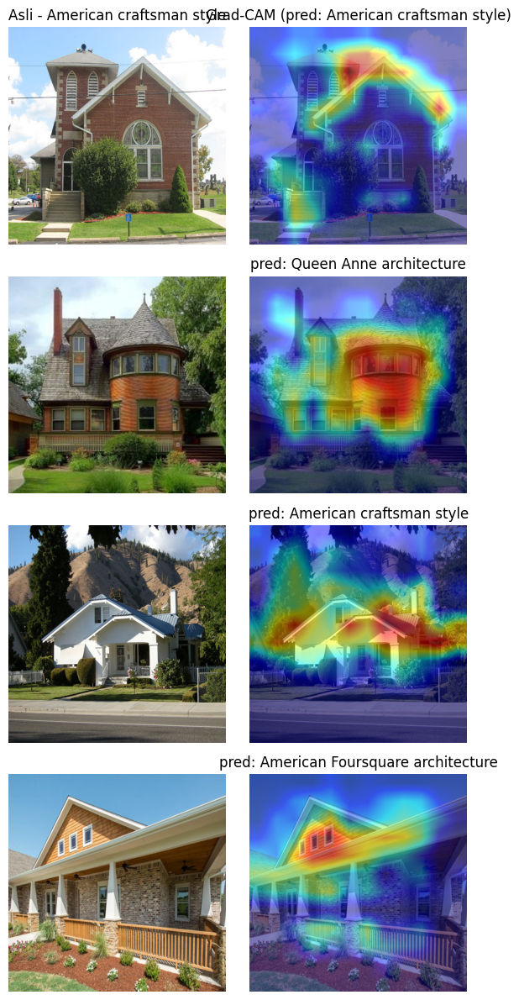

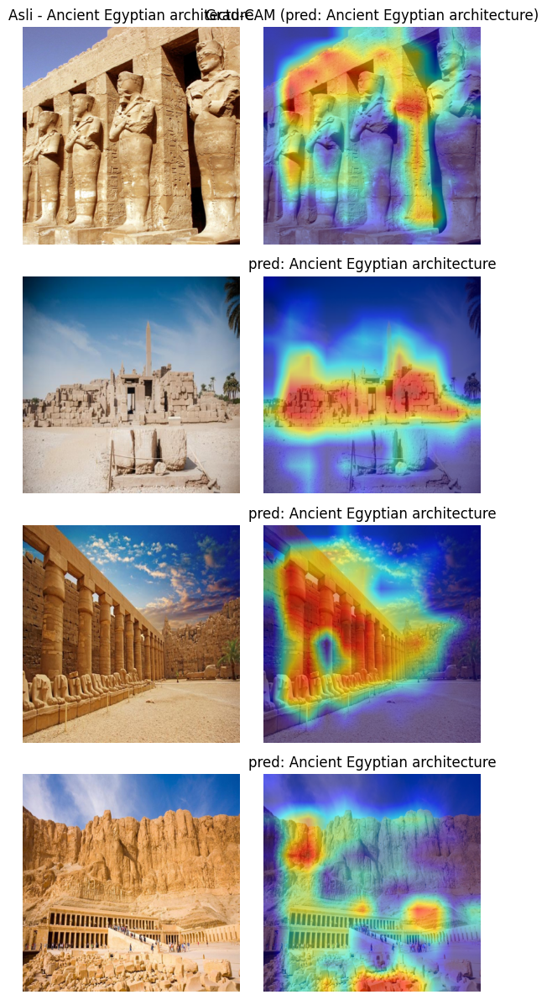

...

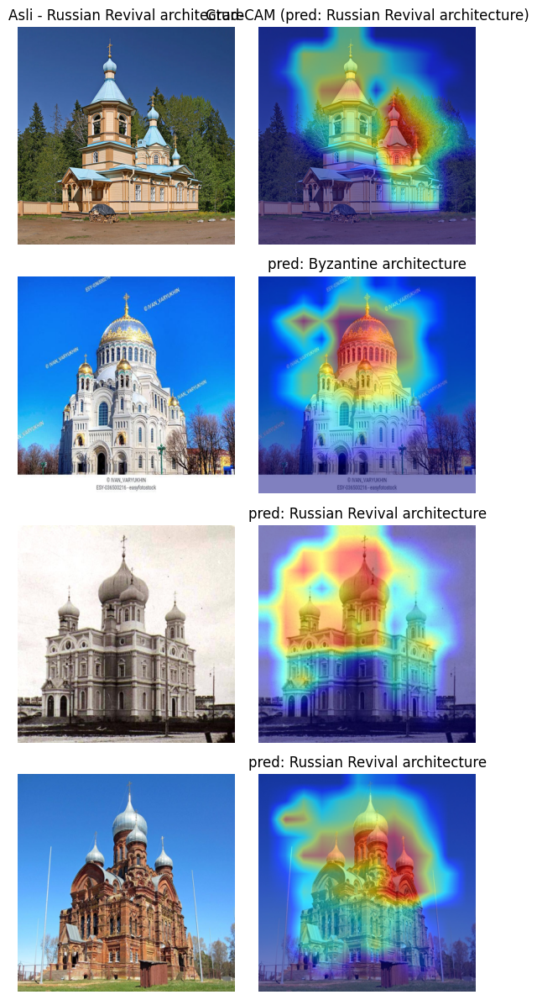

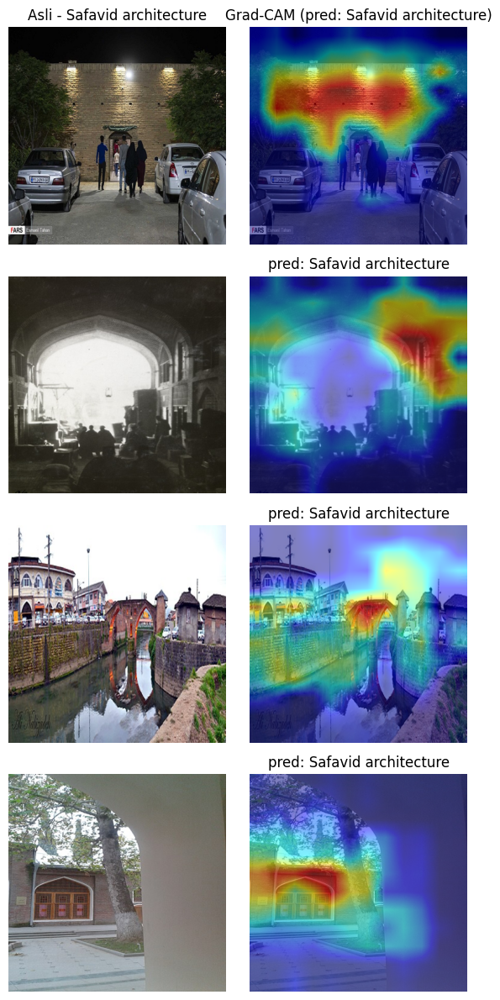

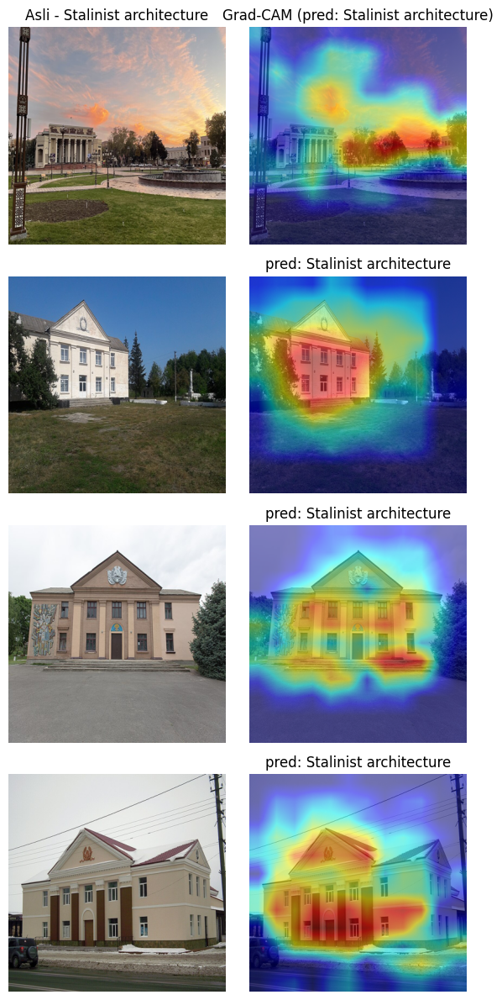

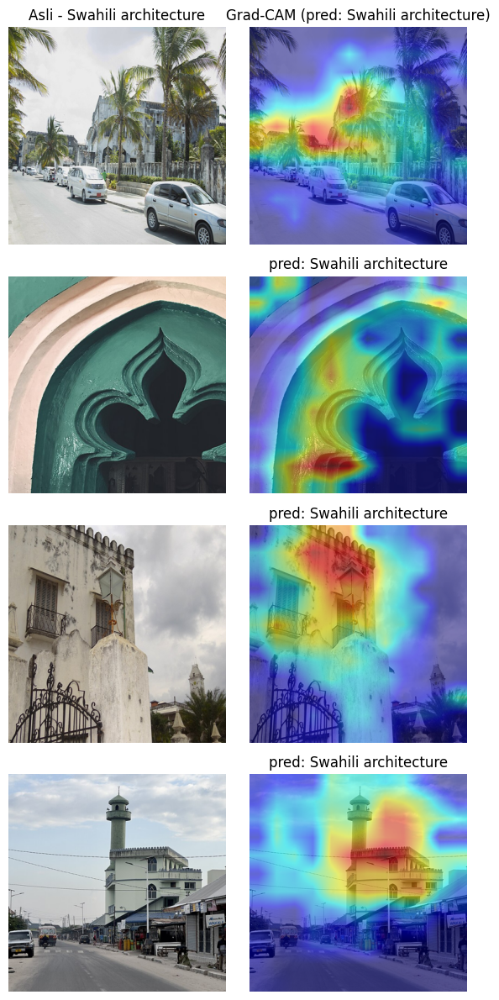

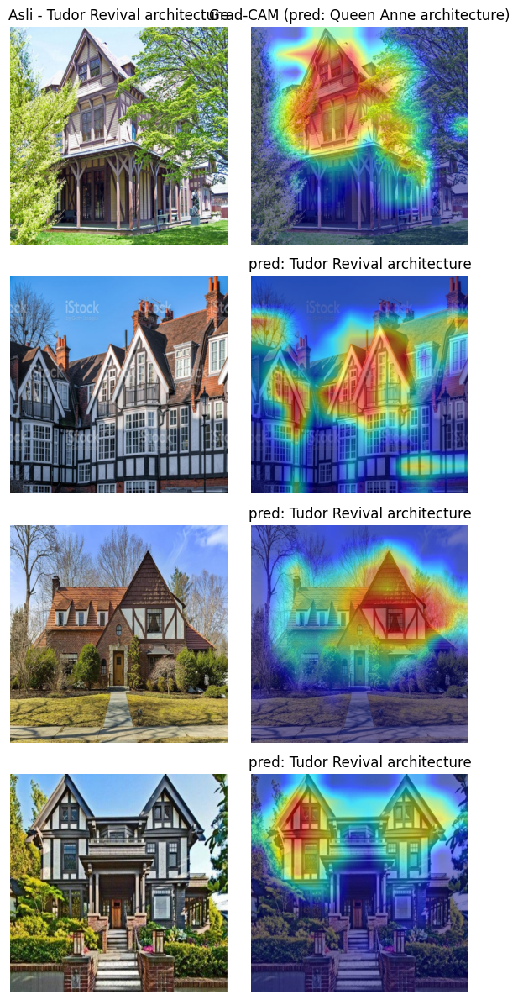

In [35]:
for class_idx, class_name in enumerate(class_names):
    candidates = samples_per_class.get(class_idx, [])[:4]
    if not candidates:
        continue

    fig, axes = plt.subplots(len(candidates), 2, figsize=(6, 3 * len(candidates)))
    if len(candidates) == 1:
        axes = axes.reshape(1, 2)

    for row, sample_idx in enumerate(candidates):
        img, label = full_dataset[sample_idx]
        input_tensor = data_transforms['val'](img).unsqueeze(0).to(device)

        cam, pred_class = compute_gradcam(gradcam_model, input_tensor)
        heatmap = gradcam_to_heatmap(cam, IMG_SIZE)

        display_img = img.resize((IMG_SIZE, IMG_SIZE))
        axes[row, 0].imshow(display_img)
        axes[row, 0].axis('off')
        axes[row, 0].set_title(f"Asli - {class_name}" if row == 0 else "")

        axes[row, 1].imshow(display_img)
        axes[row, 1].imshow(heatmap, alpha=0.5)
        axes[row, 1].axis('off')
        pred_name = class_names[pred_class]
        axes[row, 1].set_title(f"Grad-CAM (pred: {pred_name})" if row == 0 else f"pred: {pred_name}")

    plt.tight_layout()
    save_path = os.path.join(GRADCAM_DIR, f"gradcam_{class_name}.png")
    plt.savefig(save_path, dpi=120)
    plt.show()